# Arbeitsblatt 10 – Aufgabe 1.1: Gemischte Randbedingungen mit NGSolve

**Problem.** $\Omega = [0,1]^2$, $\partial\Omega = \Gamma_1 \cup \Gamma_2$ with (from Abb. 1)

* $\Gamma_1$ (blue) = bottom edge ($y=0$) **and** left edge ($x=0$)
* $\Gamma_2$ (red) = top edge ($y=1$) **and** right edge ($x=1$)

$$
\begin{aligned}
-\Delta u &= 1 && \text{in } \Omega\\
u &= 0 && \text{on } \Gamma_1 \quad\text{(Dirichlet)}\\
\frac{\partial u}{\partial n} &= 0 && \text{on } \Gamma_2 \quad\text{(Neumann)}
\end{aligned}
$$

In parts 3–4 the Neumann condition is changed to $\partial u/\partial n = 1$ on $\Gamma_2$.

> **Note on the sheet:** (1b) says $u=0$ on $\Gamma_2$, but then $\Gamma_2$ would carry *both* conditions and $\Gamma_1$ none – that cannot be meant (a Laplace problem needs exactly one condition per boundary point). It is a typo: (1b) is $u = 0$ on $\Gamma_1$.


## Part 1 – Derivation of the weak form (this goes on paper)

**Step 1: Multiply by a test function and integrate.** Take a test function $v$ with $v = 0$ on $\Gamma_1$:

$$ -\int_\Omega \Delta u\, v \,dx = \int_\Omega 1\cdot v\,dx. $$

**Step 2: Integrate by parts (Green's first identity).**

$$ -\int_\Omega \Delta u\, v\,dx = \int_\Omega \nabla u\cdot\nabla v\,dx - \int_{\partial\Omega} \frac{\partial u}{\partial n}\, v\,ds .$$

*Why?* It moves one derivative from $u$ onto $v$, so $u\in H^1$ is enough instead of $u \in C^2$.

**Step 3: Split the boundary integral** $\partial\Omega = \Gamma_1\cup\Gamma_2$. Both parts are zero, **for different reasons**:

$$ \int_{\partial\Omega} \frac{\partial u}{\partial n} v\,ds = \int_{\Gamma_1} \frac{\partial u}{\partial n}\, \underbrace{v}_{=0}\,ds + \int_{\Gamma_2} \underbrace{\frac{\partial u}{\partial n}}_{=0 \text{ (1c)}}\, v\,ds = 0 + 0 = 0. $$

* $\Gamma_1$: $\partial_n u$ is unknown there, but $v=0$ (our choice of test functions).
* $\Gamma_2$: $v$ is arbitrary there, but the boundary condition (1c) gives $\partial_n u = 0$.

**Step 4: Weak formulation.** With

$$ V = \{ v\in H^1(\Omega) : v = 0 \text{ on } \Gamma_1 \} $$

find $u\in V$ such that

$$ \boxed{\; \int_\Omega \nabla u\cdot\nabla v\,dx \;=\; \int_\Omega v\,dx \qquad \forall v\in V. \;}$$

*Remarks:*
* Dirichlet conditions are **essential** (they go into the space $V$), Neumann conditions are **natural** (they enter through the boundary integral – here with value 0).
* $a(u,v)=\int_\Omega\nabla u\cdot\nabla v\,dx$ is coercive on $V$ because $\Gamma_1$ has positive length (Friedrichs inequality) $\Rightarrow$ unique solution by Lax–Milgram.


## Part 2 – Numerical solution with FEM ($\partial_n u = 0$ on $\Gamma_2$)

The NGSolve code is a 1:1 translation of the weak form:

| Math | NGSolve |
|---|---|
| mesh / triangulation of $\Omega$ | `Mesh(unit_square.GenerateMesh(maxh=...))` |
| $V_h \subset H^1_{\Gamma_1}$, P1 elements | `H1(mesh, order=1, dirichlet="bottom\|left")` |
| trial $u$, test $v$ | `u, v = V.TnT()` |
| $a(u,v)=\int_\Omega\nabla u\cdot\nabla v\,dx$ | `a += grad(u)*grad(v)*dx` |
| $\ell(v)=\int_\Omega 1\cdot v\,dx$ | `f += 1*v*dx` |


In [9]:
from ngsolve import *
from netgen.geom2d import unit_square
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri

### Mesh and boundary names
`unit_square` already labels its four edges `bottom`, `right`, `top`, `left`. So $\Gamma_1$ = `"bottom|left"` and $\Gamma_2$ = `"top|right"`. We print them to be sure.

In [10]:
mesh = Mesh(unit_square.GenerateMesh(maxh=0.05))
print("Boundary names:", mesh.GetBoundaries())
print("Vertices:", mesh.nv, " Triangles:", mesh.ne)

Boundary names: ('bottom', 'right', 'top', 'left')
Vertices: 511  Triangles: 940


### Finite element space
`dirichlet="bottom|left"` marks the DOFs on $\Gamma_1$ as *not free*. That is how the essential condition $u = 0$ on $\Gamma_1$ is built into $V_h$. The DOFs on $\Gamma_2$ stay free – there $u$ is unknown and is determined by the equation (Neumann condition is in the weak form, not in the space).

In [11]:
V = H1(mesh, order=1, dirichlet="bottom|left")
u, v = V.TnT()
print("Total DOFs:", V.ndof, " free DOFs:", sum(V.FreeDofs()))

Total DOFs: 511  free DOFs: 470


### Bilinear form, linear form, solve
Exactly the boxed weak form: left side $\int_\Omega \nabla u\cdot\nabla v\,dx$, right side $\int_\Omega 1\cdot v\,dx$. No boundary term – it was zero.

Solving: `a.mat.Inverse(V.FreeDofs())` inverts the stiffness matrix **only on the free DOFs** (rows/columns of Dirichlet DOFs are removed). The Dirichlet DOFs keep their value from the GridFunction, which is initialised with 0 – exactly our boundary value $u=0$ on $\Gamma_1$.

In [12]:
a = BilinearForm(V)
a += grad(u) * grad(v) * dx          # a(u,v) = ∫ ∇u·∇v dx
a.Assemble()

f0 = LinearForm(V)
f0 += 1 * v * dx                     # l(v) = ∫ 1·v dx
f0.Assemble()

gfu0 = GridFunction(V)               # all values 0 → u = 0 on Γ1 automatically
gfu0.vec.data = a.mat.Inverse(V.FreeDofs()) * f0.vec

### Plot
`from ngsolve.webgui import Draw; Draw(gfu0)` gives an interactive 3D plot in Jupyter. To keep it working everywhere (also in VS Code/PDF export) we also plot with matplotlib, using the values at the mesh vertices (for P1 elements these are exactly the DOFs).

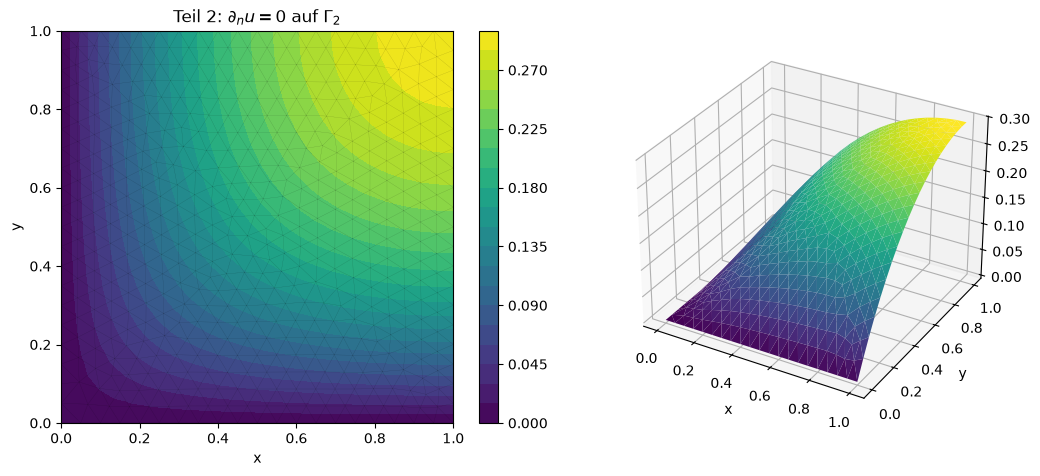

u(1,1) = 0.29449915754393585


In [13]:
def plot(gfu, title):
    pts = np.array([vtx.point for vtx in mesh.vertices])
    tris = np.array([[vv.nr for vv in el.vertices] for el in mesh.Elements(VOL)])
    vals = np.array([gfu(mesh(*p)) for p in pts])
    tri = mtri.Triangulation(pts[:, 0], pts[:, 1], tris)

    fig = plt.figure(figsize=(11, 4.5))
    ax1 = fig.add_subplot(1, 2, 1)
    cf = ax1.tricontourf(tri, vals, levels=20, cmap="viridis")
    ax1.triplot(tri, lw=0.15, color="k", alpha=0.3)
    fig.colorbar(cf, ax=ax1); ax1.set_aspect("equal")
    ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_title(title)
    ax2 = fig.add_subplot(1, 2, 2, projection="3d")
    ax2.plot_trisurf(tri, vals, cmap="viridis")
    ax2.set_xlabel("x"); ax2.set_ylabel("y")
    plt.tight_layout(); plt.show()

plot(gfu0, r"Teil 2: $\partial_n u = 0$ auf $\Gamma_2$")
print("u(1,1) =", gfu0(mesh(1, 1)))

### Plausibility check (why the result makes sense)
* $u=0$ on the bottom and left edge ✔ (Dirichlet).
* The level lines meet the top and right edges **at right angles** ⇒ $\partial_n u = 0$ ✔ (the solution is "flat" in the normal direction).
* Maximum in the corner $(1,1)$: heat (source $f=1$) can only leave through $\Gamma_1$, the point farthest away from $\Gamma_1$ is the hottest.

**Mirror trick:** $\partial_n u=0$ on $x=1$ and $y=1$ means the solution is symmetric there. If we reflect at $x=1$ and $y=1$, we get the pure Dirichlet problem $-\Delta U = 1$ on $[0,2]^2$, $U=0$ on the whole boundary, and $u(1,1)$ = centre value of that problem. Its centre value on $[0,1]^2$ is $\approx 0.07367$, and scaling the domain by 2 scales $u$ by $2^2 = 4$ ⇒ $u(1,1) \approx 0.2947$. We check this:

In [14]:
mesh2 = Mesh(unit_square.GenerateMesh(maxh=0.05))
V2 = H1(mesh2, order=1, dirichlet="bottom|right|top|left")
w, z = V2.TnT()
a2 = BilinearForm(grad(w) * grad(z) * dx).Assemble()
f2 = LinearForm(1 * z * dx).Assemble()
U = GridFunction(V2); U.vec.data = a2.mat.Inverse(V2.FreeDofs()) * f2.vec
print("4 * U(0.5,0.5) on [0,1]^2 :", 4 * U(mesh2(0.5, 0.5)))
print("u(1,1) mixed problem       :", gfu0(mesh(1, 1)))

4 * U(0.5,0.5) on [0,1]^2 : 0.293860099611241
u(1,1) mixed problem       : 0.29449915754393585


## Part 3 – Weak form with $\partial_n u = 1$ on $\Gamma_2$ (this goes on paper)

Steps 1 and 2 are identical. Only in Step 3 something changes: on $\Gamma_2$ we now insert $\partial_n u = 1$ instead of $0$, so the $\Gamma_2$ term **no longer vanishes**:

$$ \int_{\partial\Omega} \frac{\partial u}{\partial n} v\,ds = \int_{\Gamma_1} \frac{\partial u}{\partial n}\, \underbrace{v}_{=0}\,ds + \int_{\Gamma_2} \underbrace{\frac{\partial u}{\partial n}}_{=1}\, v\,ds = \int_{\Gamma_2} v\,ds .$$

Put into Step 2: $\int_\Omega \nabla u\cdot\nabla v\,dx - \int_{\Gamma_2} v\,ds = \int_\Omega v\,dx$. Bring the known term to the right:

Find $u \in V$ (same $V$) such that

$$ \boxed{\;\int_\Omega \nabla u\cdot\nabla v\,dx = \int_\Omega v\,dx + \int_{\Gamma_2} v\,ds \qquad \forall v\in V.\;} $$

* The **space $V$ and the bilinear form do not change**. Only the right-hand side gets an extra boundary integral.
* Physical meaning: $\partial_n u = 1 > 0$ with outward normal $n$ means $u$ *increases* towards the outside, i.e. heat flows **into** the domain through $\Gamma_2$. So we expect a larger solution than in part 2.


## Part 4 – Numerical solution with $\partial_n u = 1$
Same matrix `a`. The linear form gets one extra line: `ds("top|right")` integrates only over $\Gamma_2$.

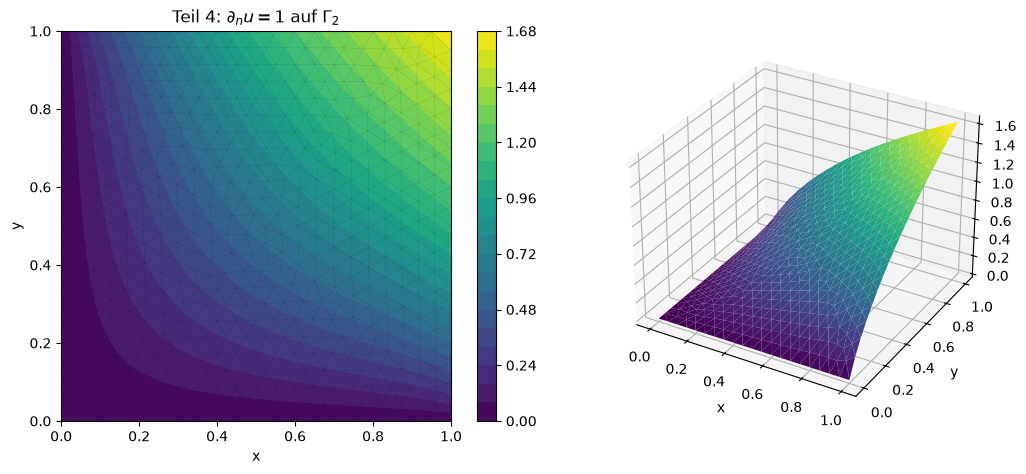

u(1,1) = 1.6447624581491123


In [15]:
f1 = LinearForm(V)
f1 += 1 * v * dx                     # ∫ 1·v dx
f1 += 1 * v * ds("top|right")        # NEW: ∫_Γ2 1·v ds  (Neumann term)
f1.Assemble()

gfu1 = GridFunction(V)
gfu1.vec.data = a.mat.Inverse(V.FreeDofs()) * f1.vec
plot(gfu1, r"Teil 4: $\partial_n u = 1$ auf $\Gamma_2$")
print("u(1,1) =", gfu1(mesh(1, 1)))

### Check of the Neumann condition
We numerically integrate the normal derivative over each edge. Important: in FEM the Neumann condition is only satisfied **weakly**, i.e. approximately. P1 gradients are piecewise constant and only accurate to $O(h)$, so expect values a few percent off (≈0.94 instead of 1). Try `maxh=0.01` or `order=2` and watch them approach 0 / 1 / −1 / −3.

Also a global check (divergence theorem): $\int_{\partial\Omega} \partial_n u\,ds = \int_\Omega \Delta u\,dx = -\int_\Omega 1\,dx = -1$. On $\Gamma_2$ (length 2) the flux is $+2$, so on $\Gamma_1$ it must be $-3$: all the heat from the source (1) plus what comes in through $\Gamma_2$ (2) leaves through $\Gamma_1$.

In [16]:
# P1 gradients live on the triangles, so we evaluate them just inside the boundary
# (eps away) and average over many sample points ≈ boundary integral.
eps, s = 1e-9, np.linspace(0, 1, 4001)[1:-1]
def dgrad(gf, x, y): return np.array(grad(gf)(mesh(x, y)))

for dn, gf in [(0, gfu0), (1, gfu1)]:   # dn = prescribed ∂u/∂n on Γ2
    top    = np.mean([ dgrad(gf, t, 1 - eps)[1] for t in s])   # n = (0, 1)
    right  = np.mean([ dgrad(gf, 1 - eps, t)[0] for t in s])   # n = (1, 0)
    bottom = np.mean([-dgrad(gf, t, eps)[1]     for t in s])   # n = (0,-1)
    left   = np.mean([-dgrad(gf, eps, t)[0]     for t in s])   # n = (-1,0)
    print(f"∂u/∂n={dn} on Γ2: mean du/dn top={top:.3f}, right={right:.3f} | "
          f"flux over Γ1 = {bottom + left:.3f} (expected {-1 - 2*dn})")

∂u/∂n=0 on Γ2: mean du/dn top=0.003, right=0.002 | flux over Γ1 = -0.951 (expected -1)
∂u/∂n=1 on Γ2: mean du/dn top=0.941, right=0.944 | flux over Γ1 = -2.852 (expected -3)


## Summary (for paper)
| | Part 1/2 ($\partial_n u=0$) | Part 3/4 ($\partial_n u=1$) |
|---|---|---|
| Space | $V=\{v\in H^1(\Omega): v=0 \text{ on } \Gamma_1\}$ | same |
| $a(u,v)$ | $\int_\Omega \nabla u\cdot\nabla v\,dx$ | same |
| $\ell(v)$ | $\int_\Omega v\,dx$ | $\int_\Omega v\,dx + \int_{\Gamma_2} v\,ds$ |
| NGSolve change | – | `f1 += 1*v*ds("top\|right")` |
